# 03 · Stimulus features (the "cards")

The organisers' notebook 01 describes each video with **AlexNet** on 8 frames. We describe every
video (1,000 training + 102 test) with several complementary feature sets. Each was tested on
held-out training videos (see `past_trials/experiment_log.md`):

| block | model | what it captures | used in final model |
|---|---|---|---|
| `clip` | CLIP ViT-B/32, 8 frames averaged | *what* is in the picture (objects, scenes) | yes (weight 1.0) |
| `mae` | VideoMAE (Kinetics), 16 frames, layers 4/8/12 | motion and actions | yes (0.6) |
| `low` | no model: brightness, contrast, saturation, motion, edges, scene cuts, loudness, sound onsets, every 0.1 s | low-level timing the early visual/auditory brain reacts to | yes (0.6) |
| `ast4` | Audio Spectrogram Transformer (AudioSet), layer 4 | what the **sound** is | yes (0.5) |

Everything is cached in `cache/`. The first run takes about 1 hour (most of it decoding video on
the CPU; models run on the GPU if there is one). Later runs load the cache in seconds.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repo root, so `mindreading` imports work
import numpy as np
import matplotlib.pyplot as plt
from mindreading.config import DATA_DIR, RESULTS_DIR, WEIGHTS_DIR, SUBMISSION_DIR
print('data folder:', DATA_DIR)

data folder: <repo>\data


In [2]:
from mindreading.video_features import extract_clip
from mindreading.features import EXTRACTORS, LOWLEVEL_NAMES
feats = {'clip_b32': extract_clip()}
for name in ('lowlevel', 'videomae', 'ast'):
    feats[name] = EXTRACTORS[name]()
for name, f in feats.items():
    print(f'{name:9s}', {k: v.shape for k, v in f.items() if k != 'ids'})

[transformers] `VideoMAEImageProcessor` requires torchvision (not installed); falling back to `VideoMAEImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `VideoMAEImageProcessorPil` directly to silence this warning.


Loading weights:   0%|          | 0/182 [00:00<?, ?it/s]

[transformers] VideoMAEModel LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
fc_norm.weight    | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 
fc_norm.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


clip_b32  {'frames': (1102, 8, 512), 'mean': (1102, 512)}
lowlevel  {'timecourse': (1102, 30, 8)}
videomae  {'layers': (1102, 3, 768)}
ast       {'layers': (1102, 3, 768), 'silent': (1102,)}


<repo>\.venv\Lib\site-packages\transformers\audio_utils.py:829: UserWarning: At least one mel filter has all zero values. The value for `num_mel_filters` (128) may be set too high. Or, the value for `num_frequency_bins` (257) may be set too low.
  warnings.warn(


### What the low-level time courses look like
Four videos, the 8 low-level signals over the 3 s (z-scored over all videos). The brain's first
responses (~0.1–0.2 s) follow exactly this kind of signal: changes in light, motion and sound.

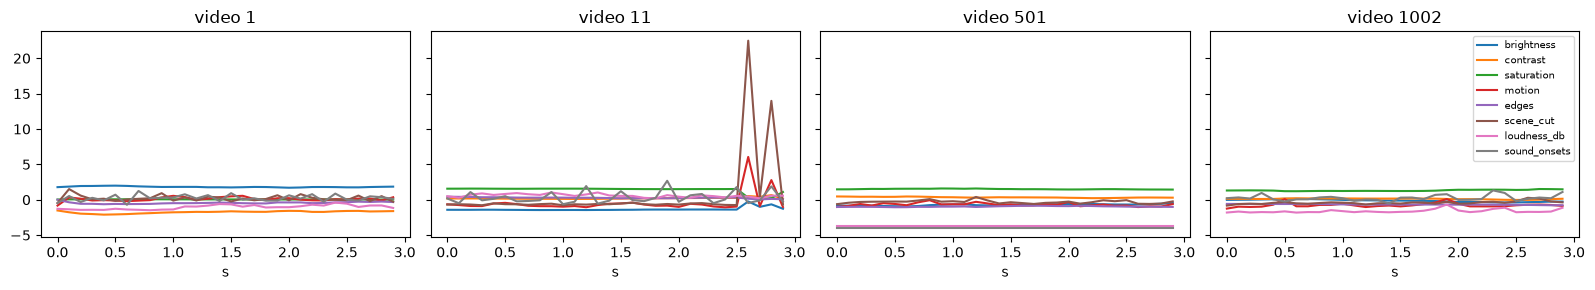

videos without sound: 43


In [3]:
tc = feats['lowlevel']['timecourse']
z = (tc - tc.mean((0, 1))) / tc.std((0, 1))
t = np.arange(30) / 10
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, row in zip(axes, [0, 10, 500, 1001]):
    ax.plot(t, z[row]); ax.set_title(f"video {feats['lowlevel']['ids'][row]}"); ax.set_xlabel('s')
axes[-1].legend(LOWLEVEL_NAMES, fontsize=7, loc='upper right'); plt.tight_layout(); plt.show()
print('videos without sound:', int(feats['ast']['silent'].sum()))

### Sanity check: do similar videos get similar CLIP cards?
For three test videos: the most similar training videos (cosine similarity, 1 = identical).

In [4]:
from mindreading.video_features import lookup
train_ids, test_ids = np.arange(1, 1001), np.arange(1001, 1103)
A, B = lookup(feats['clip_b32'], test_ids), lookup(feats['clip_b32'], train_ids)
sim = A @ B.T
for row in [0, 1, 2]:
    best = np.argsort(-sim[row])[:3]
    print(f'test video {test_ids[row]}: most similar training videos',
          [(int(train_ids[b]), round(float(sim[row, b]), 2)) for b in best])

test video 1001: most similar training videos [(415, 0.82), (725, 0.74), (782, 0.74)]
test video 1002: most similar training videos [(45, 0.92), (128, 0.9), (86, 0.9)]
test video 1003: most similar training videos [(880, 0.77), (103, 0.77), (301, 0.77)]
